# Bitcoin: finding out you have nothing

**Our first backtest called the direction of tomorrow's Bitcoin price right on 79% of days. The honest number was 57%, no better than always saying "up".**

Everyone who learns forecasting tries it on a price sooner or later. We do it here the way a first notebook usually does: a table of past prices, one smoothed column to tame the noise, a linear regression, a test on the last year and a half. The result looks like a money machine. Then we run the same model through TimeGym, which only ever hands a model the past, and the edge disappears. The rest of the notebook finds where it came from, and uses the scorecard to tell "the model is too weak" from "there is nothing here to find".

*Data: daily Bitcoin price in US dollars, July 2010 to July 2021, from the Monash Time Series Forecasting Archive, CC BY 4.0 ([source and license](data/README.md#bitcoin)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from timegym import LastValueForecaster, Pipeline, cases_from_series

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The price

We use the price from 2014 on, train on the years up to 2019 and test on every day from January 2020 to July 2021. The plot uses a log axis, so equal steps up the axis are equal percentage moves.

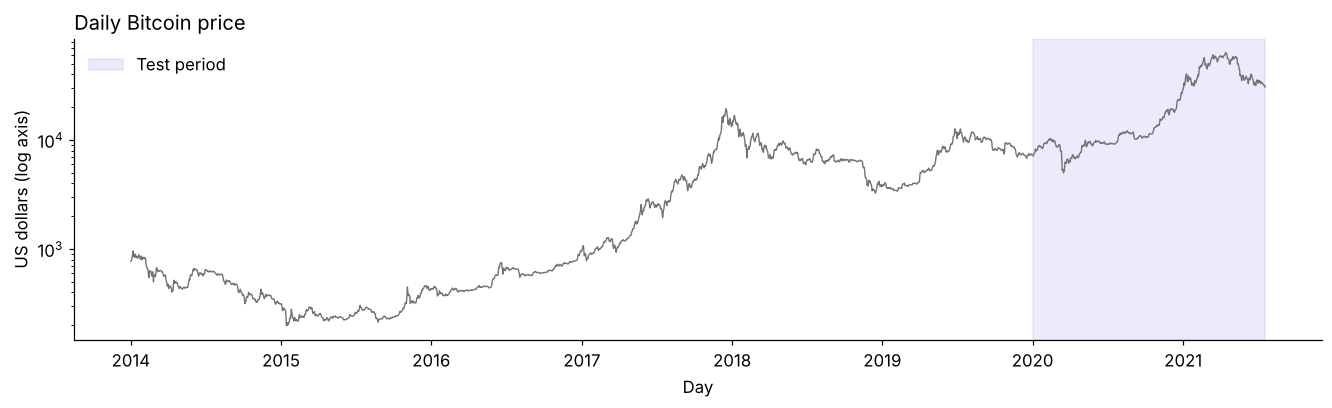

2,757 days; 566 of them in the test period, where the price went from $7,238 to $30,593.


In [2]:
price = load("bitcoin").loc["2014-01-01":]
test_start = "2020-01-01"

fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
ax.plot(price.index, price["price"], color="0.45", linewidth=0.9)
ax.axvspan(pd.Timestamp(test_start), price.index[-1], color="#0000CC", alpha=0.08, label="Test period")
ax.set(yscale="log", title="Daily Bitcoin price", xlabel="Day", ylabel="US dollars (log axis)")
ax.legend(loc="upper left")
plt.show()
print(f"{len(price):,} days; {int((price.index >= test_start).sum())} of them in the test period, "
      f"where the price went from ${price['price'].loc[test_start]:,.0f} to ${price['price'].iloc[-1]:,.0f}.")

## The notebook everyone writes

Each day we want tomorrow's price. The table below has one row per day: the price to predict, the prices of the 14 days before it, and one extra column. Daily prices are jumpy, so we smooth them with a 7-day average and give the model yesterday's smoothed price as well. Then a linear regression, trained up to 2019 and scored on the test period.

We score three things: the average miss in dollars, R² (the share of the price's variation the forecast explains), and how often the forecast called the direction of the day's move, up or down from yesterday.

In [3]:
table = pd.DataFrame({"price": price["price"]})
for days in range(1, 15):
    table[f"price_{days}_days_ago"] = table["price"].shift(days)
smooth = table["price"].rolling(7, center=True).mean()   # a 7-day average to tame the daily noise
table["smooth_price_yesterday"] = smooth.shift(1)
table = table.dropna()

train, test = table.loc[:"2019-12-31"], table.loc[test_start:]
features = [column for column in table.columns if column != "price"]
model = LinearRegression().fit(train[features], train["price"])


def score(forecast, actual, yesterday):
    "Average miss, R² and the share of days with the direction of the move called right."
    return {"average miss ($)": np.mean(np.abs(actual - forecast)), "R²": r2_score(actual, forecast),
            "direction right (%)": 100 * np.mean(np.sign(forecast - yesterday) == np.sign(actual - yesterday))}


results = pd.DataFrame({
    "Notebook model": score(model.predict(test[features]), test["price"], test["price_1_days_ago"]),
    "Yesterday's price": score(test["price_1_days_ago"], test["price"], test["price_1_days_ago"]),
}).T
results.loc["Yesterday's price", "direction right (%)"] = np.nan   # it never calls a move
display(results.round({"average miss ($)": 0, "R²": 4, "direction right (%)": 1}))
assert results.loc["Notebook model", "direction right (%)"] > 75

,average miss ($),R²,direction right (%)
Notebook model,350.0,0.9988,79.4
Yesterday's price,586.0,0.9963,NaN


The model calls the direction right on almost four days out of five and misses by about 40% less than repeating yesterday's price. If this were real it would be worth a fortune.

Notice R² on the way. The model's 0.9988 sounds like proof, but repeating yesterday's price gets 0.9963. On a price series nearly anything has an R² close to 1, because today's price is always close to yesterday's. It says nothing about an edge.

## The same model, run so that it cannot see ahead

TimeGym runs a forecast differently. We don't build the table of inputs: we hand over the series and say which days to forecast. For each of those days the model gets the history up to the day before and the date to forecast, and nothing else. The pipeline builds the inputs from that history itself.

`Pipeline(LinearRegression(), window_length=14)` is the same model: a linear regression on the last 14 prices. We leave out the smoothed column, because an average of past prices is a weighted sum of them, and a linear regression on those prices already has it. `cases_from_series` makes one case per test day, and `LastValueForecaster`, which repeats the last price it saw, runs on the same cases as the reference.

In [4]:
series = price.astype(float)
first_test_day = int((series.index < test_start).sum())
cases = cases_from_series(series, origins=range(first_test_day, len(series)), horizon=1, name="bitcoin")

linear = Pipeline(LinearRegression(), window_length=14, name="Linear on 14 days")
runs = {"Same model, through TimeGym": linear.run(cases=cases, keep_data=True),
        "Last value, through TimeGym": Pipeline(LastValueForecaster()).run(cases=cases, keep_data=True)}

actual = np.array([case.observed.iloc[0, 0] for case in cases])
yesterday = np.array([case.task.history.iloc[-1, 0] for case in cases])
for name, run in runs.items():
    forecast = np.array([entry.forecast.point[0, 0] for entry in run.cases])
    results.loc[name] = score(forecast, actual, yesterday)
results.loc["Last value, through TimeGym", "direction right (%)"] = np.nan
display(results.round({"average miss ($)": 0, "R²": 4, "direction right (%)": 1}))

up_days = 100 * np.mean(actual > yesterday)
checks = runs["Same model, through TimeGym"].report.summary["status_counts"]
print(f"{len(cases)} forecasts, each made from the history before its day. "
      f"Output checks passed: {checks['PASS']}, failed: {checks['FAIL']}.")
print(f"The price rose on {up_days:.1f}% of the test days, so always saying 'up' is right {up_days:.1f}% of the time.")
honest = results.loc["Same model, through TimeGym"]
assert honest["direction right (%)"] < up_days + 2          # no better than always saying "up"
assert honest["average miss ($)"] > 0.98 * results.loc["Last value, through TimeGym", "average miss ($)"]

,average miss ($),R²,direction right (%)
Notebook model,350.0,0.9988,79.4
Yesterday's price,586.0,0.9963,NaN
"Same model, through TimeGym",596.0,0.9961,56.7
"Last value, through TimeGym",586.0,0.9963,NaN


566 forecasts, each made from the history before its day. Output checks passed: 566, failed: 0.
The price rose on 57.8% of the test days, so always saying 'up' is right 57.8% of the time.


Run this way, the model calls the direction right on 57% of days. The price rose on 58% of the test days, so someone who said "up" every morning did slightly better. Its average miss is about ten dollars larger than that of repeating the last price. The edge is gone.

The two runs use the same learner and the same 14 past prices. (TimeGym also refits the model each day on all the history so far, which changes little here.) The real difference is the column we left out.

## Where the 79% came from

`rolling(7, center=True)` centers each average on its own day: three days before, the day itself and three days after. Yesterday's smoothed price therefore contains today's price, which is the number we are predicting, and the prices of the next two days.

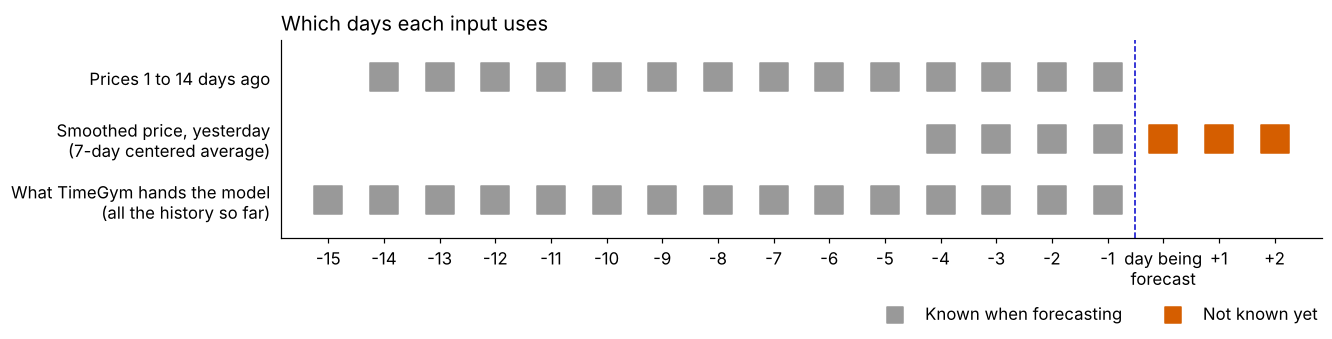

,average miss ($),R²,direction right (%)
Notebook model,350.0,0.9988,79.4
Yesterday's price,586.0,0.9963,NaN
"Same model, through TimeGym",596.0,0.9961,56.7
"Last value, through TimeGym",586.0,0.9963,NaN
"Notebook model, average of past days only",589.0,0.9964,57.3


In [5]:
days = np.arange(-15, 3)
uses = {"Prices 1 to 14 days ago": (days >= -14) & (days <= -1),
        "Smoothed price, yesterday\n(7-day centered average)": (days >= -4) & (days <= 2),
        "What TimeGym hands the model\n(all the history so far)": days <= -1}
fig, ax = plt.subplots(figsize=(12, 3), layout="constrained")
for row, used in enumerate(uses.values()):
    known = used & (days < 0)
    ax.scatter(days[known], np.full(known.sum(), row), marker="s", s=320, color="0.6",
               label="Known when forecasting" if row == 0 else None)
    ahead = used & (days >= 0)
    ax.scatter(days[ahead], np.full(ahead.sum(), row), marker="s", s=320, color="#D55E00",
               label="Not known yet" if row == 1 else None)
ax.axvline(-0.5, color="#0000CC", linestyle="--", linewidth=1)
ax.set(yticks=range(len(uses)), yticklabels=list(uses), ylim=(len(uses) - 0.4, -0.6), xticks=days,
       xticklabels=["day being\nforecast" if d == 0 else f"{d:+d}" for d in days],
       title="Which days each input uses")
ax.tick_params(left=False)
fig.legend(loc="outside lower right", ncols=2, markerscale=0.6)
plt.show()

table["trailing_average_yesterday"] = table["price"].shift(1).rolling(7).mean()   # only past days
fixed = table.dropna()
train, test = fixed.loc[:"2019-12-31"], fixed.loc[test_start:]
honest_features = [f"price_{days}_days_ago" for days in range(1, 15)] + ["trailing_average_yesterday"]
refit = LinearRegression().fit(train[honest_features], train["price"])
results.loc["Notebook model, average of past days only"] = score(
    refit.predict(test[honest_features]), test["price"], test["price_1_days_ago"])
display(results.round({"average miss ($)": 0, "R²": 4, "direction right (%)": 1}))
assert results.loc["Notebook model, average of past days only", "direction right (%)"] < up_days + 2

With the average taken over past days only, the notebook's own code gives the honest answer too: direction right on 57% of days, and a miss as large as yesterday's price. One argument, `center=True`, was the whole edge.

TimeGym did not find that bug. It cannot see how a table was prepared outside it, and the [scope page](../docs/concepts/scope.md#the-model-never-sees-the-future) says so. What it did was make the mistake impossible in its own run, because a model inside a TimeGym test has nowhere to get a future value from. Two numbers that should have agreed did not, and that told us where to look.

## Too weak a model, or nothing to find?

A model that ties with "repeat the last price" has two possible explanations. The model may be too weak to find the pattern, or there may be no pattern in these inputs. The backtest cannot tell them apart. The scorecard can, because it tests the model on generated series where we know what there is to find.

Linear on 14 days  Last value
Kind of series                      Noise                                    
Pure noise                          Low noise                  94          56
                                    High noise                 94          56
Noise around a fixed level          Low noise                  94          56
                                    High noise                 94          56
Straight-line trend                 Low noise                  90          10
                                    High noise                 89          43
Repeating seasonal cycle            Low noise                  78           3
                                    High noise                 79          28
Trend + seasonal cycle              Low noise                  74           2
                                    High noise                 73          21
Sudden level shift                  Low noise                  51          70
                                    High noise                 77          70
Mean reversion (AR(1)): shocks fade Low noise                  85          78
                                    High noise                 93          72
Irregular cycles (AR(2))            Low noise                  84          35
                                    High noise                 90          47
Random walk: shocks never fade      Low noise                  92          99
                                    High noise                 93          87
Random walk with drift              Low noise                  61          64
                                    High noise                 47          71

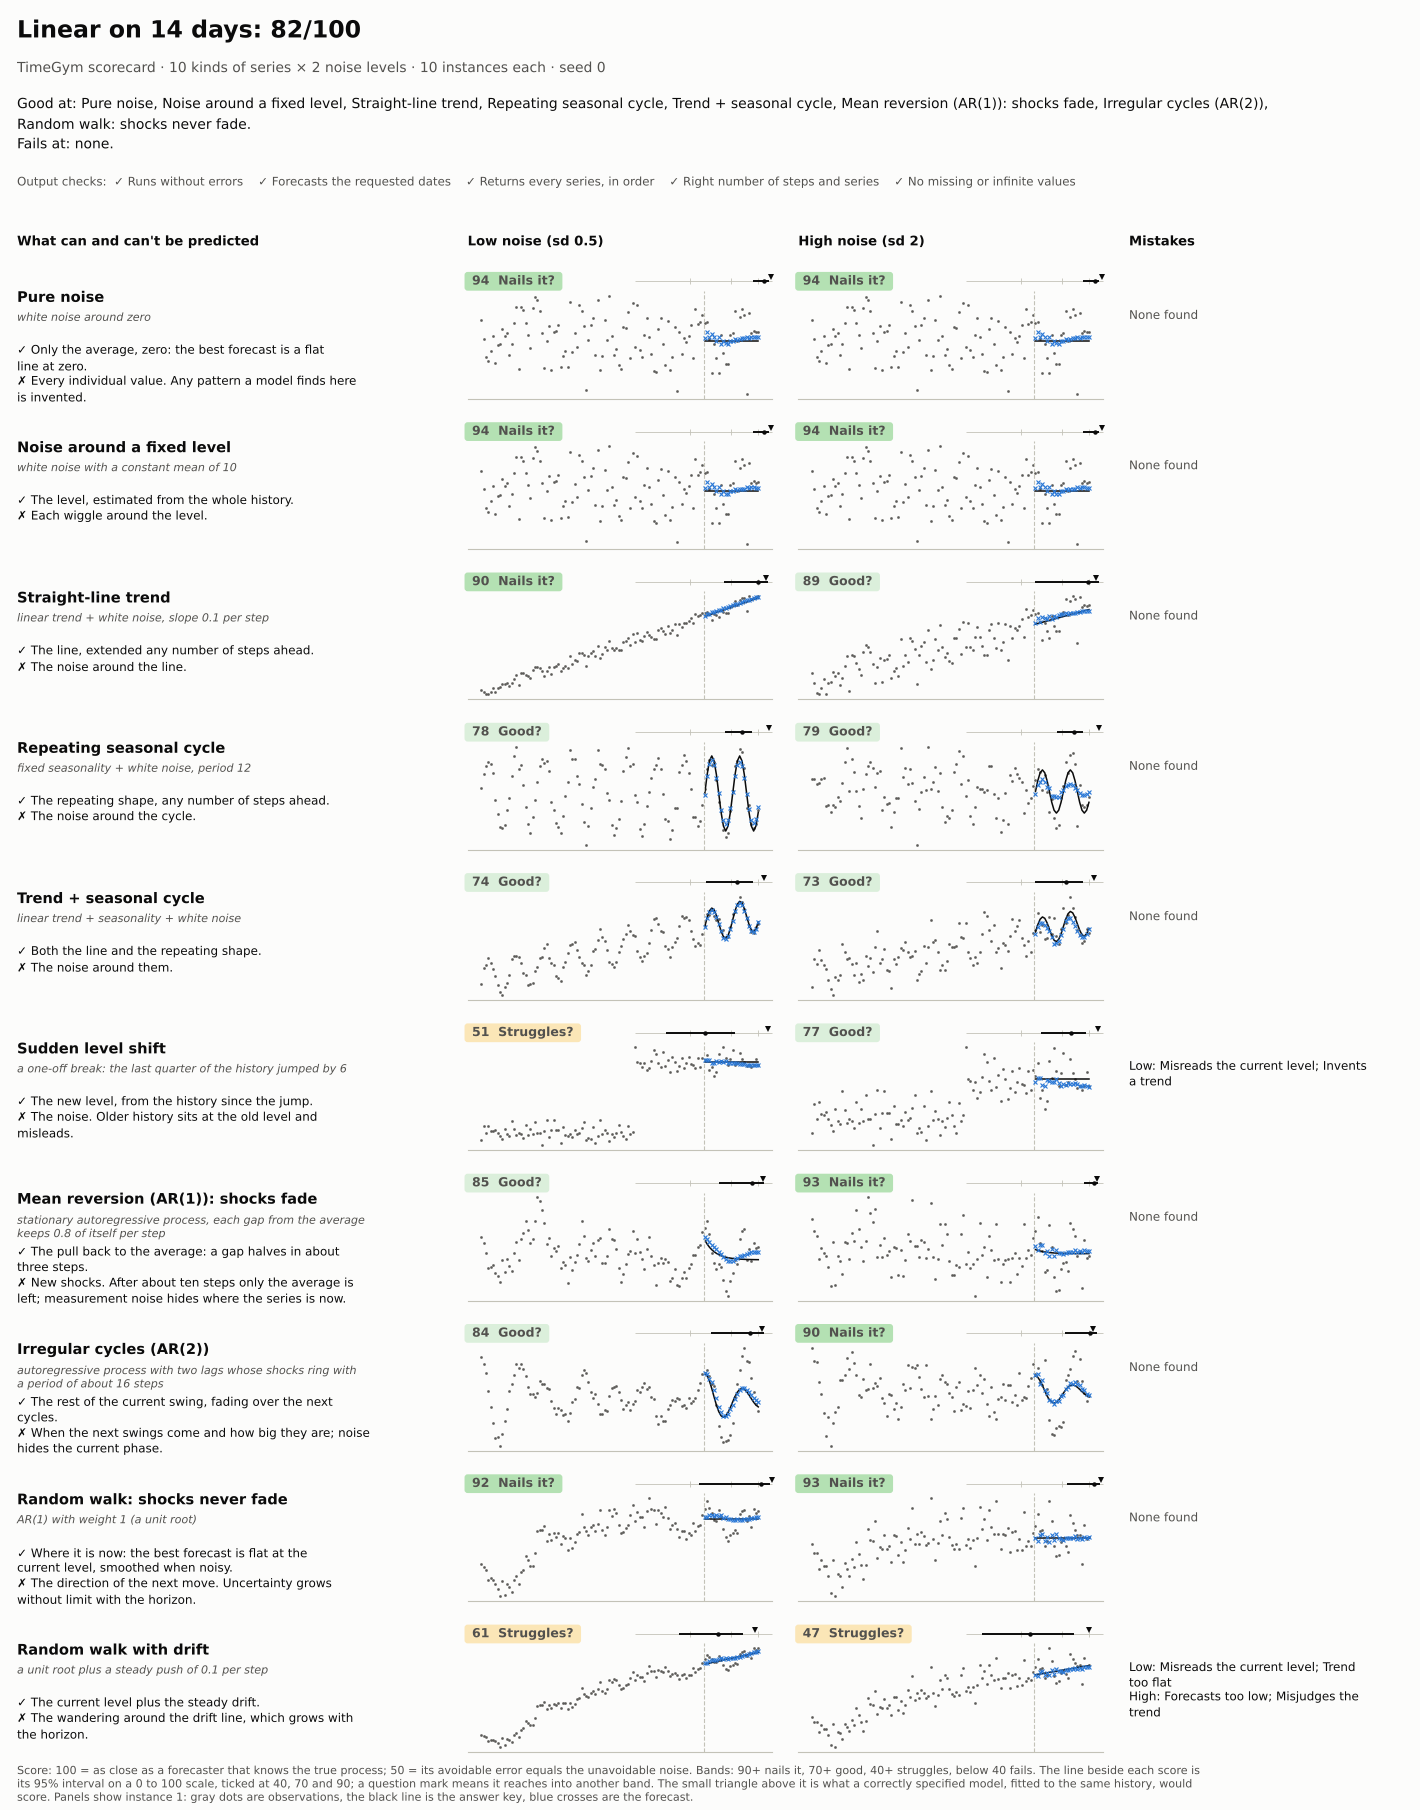

In [6]:
linear_card = linear.run().scorecard
last_value_card = Pipeline(LastValueForecaster(), name="Last value").run().scorecard

side_by_side = pd.DataFrame({
    "Kind of series": linear_card.table["title"], "Noise": linear_card.table["noise"],
    "Linear on 14 days": linear_card.table["score"], "Last value": last_value_card.table["score"],
}).set_index(["Kind of series", "Noise"]).round(0).astype(int)
display(side_by_side)
linear_card

The linear model scores 82 and the last value 51. Wherever a generated series has a shape to learn, the linear model learns it and the last value cannot: 90 against 10 on a straight-line trend at low noise, 78 against 3 on a seasonal cycle, 84 against 35 on irregular cycles. This is not a weak model.

Now read the random-walk rows. A random walk is a series where each day's move is independent of everything before it. The card's left column says what can be predicted there: where the series is now, and nothing about the direction of the next move. On those rows the two forecasters are level, 92 and 93 for the linear model against 99 and 87 for the last value, and with a drift the last value is ahead.

Our backtest looks like those rows. A model that beats the last value by a wide margin wherever there is something to learn, and only ties with it on Bitcoin, is telling us that the last 14 daily prices hold nothing more than the current price.

In [7]:
scores = side_by_side.reset_index().assign(pattern=linear_card.table["pattern"]).groupby("pattern")[
    ["Linear on 14 days", "Last value"]].mean()
learnable = ["trend", "seasonal", "trend_seasonal", "cycles"]  # kinds of series with a shape to learn
assert (scores.loc[learnable, "Linear on 14 days"] > scores.loc[learnable, "Last value"] + 20).all()
print(f"Overall: Linear on 14 days {linear_card.score:.0f}, Last value {last_value_card.score:.0f}.")

Overall: Linear on 14 days 82, Last value 51.


## What TimeGym added

- A run in which the model cannot see ahead, whatever we do. The 79% could not be reproduced there, which is how we learned it was not real.
- A reference forecaster on exactly the same 566 days, in one line. Against it, the honest model has nothing.
- A scorecard that rules out "the model is too weak": the same model finds trends, seasons and cycles when they exist.

The result of this project is a "no", and it took a few minutes to reach. The alternative was finding out with money.

## Change one thing

- Forecast a week ahead: `cases_from_series(series, origins=range(first_test_day, len(series) - 6, 7), horizon=7)`.
- Forecast percentage moves in place of dollars with `target_transform=ComposedTransform([LogTransform(), DifferenceTransform()])` from `timegym.target`.
- Plant a pattern you know is there, such as a weekly cycle of 1% added to the price, and see how large it must be before the model beats the last value. That tells you how small an edge this test could have found.
- `load("bitcoin", full=True)` adds 17 more daily series, such as transactions, search interest and tweets. Before using one as an input, ask at what time of day its value for a given day was actually known.

**What this doesn't show.** One linear model on 14 past prices found nothing in daily prices over 19 months that were mostly a bull run. That says nothing about other inputs, other horizons or faster data, and "no edge found" is not proof that none exists. TimeGym prevents leaks inside its own tests; it does not inspect a table of inputs you prepared elsewhere.

**Related:** [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) checks a winning model for the same kind of leak, [Quick start](../tutorials/01_quick_start.ipynb) reads the last-value scorecard row by row, and [What TimeGym does and does not test](../docs/concepts/scope.md) sets out the limits. More examples are on the [examples page](../docs/examples.md).